In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
# Cell 1: Imports and configuration

import copy
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms, models
from torchvision.models import ResNet50_Weights

SEED = 42
BATCH_SIZE = 64
FEATURE_EPOCHS = 3
FINETUNE_EPOCHS = 3
LEARNING_RATE_HEAD = 1e-3
LEARNING_RATE_BACKBONE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)# Cell 1: Imports and configuration

import copy
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms, models
from torchvision.models import ResNet50_Weights

SEED = 42
BATCH_SIZE = 64
FEATURE_EPOCHS = 3
FINETUNE_EPOCHS = 3
LEARNING_RATE_HEAD = 1e-3
LEARNING_RATE_BACKBONE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)

Device: cuda
Device: cuda


In [3]:
# Cell 2: CIFAR-10 transforms and data loaders

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15,
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_augmented = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform,
)

train_eval = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=eval_transform,
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=eval_transform,
)

# Fixed 90/10 train-validation split.
n_train = int(0.9 * len(train_augmented))
n_val = len(train_augmented) - n_train

split_generator = torch.Generator().manual_seed(SEED)
train_indices, val_indices = random_split(
    range(len(train_augmented)),
    [n_train, n_val],
    generator=split_generator,
)

train_dataset = Subset(
    train_augmented, train_indices.indices
)
val_dataset = Subset(
    train_eval, val_indices.indices
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
)

CLASSES = train_augmented.classes

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))
print("Classes:", CLASSES)

100%|██████████| 170M/170M [42:06<00:00, 67.5kB/s]   


Training: 45000
Validation: 5000
Test: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [4]:
# Cell 3: Load pretrained ResNet50

weights = ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

# Freeze every pretrained parameter initially.
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the ImageNet classifier with a CIFAR-10 classifier.
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, len(CLASSES))

model = model.to(DEVICE)

trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
total_parameters = sum(p.numel() for p in model.parameters())

print(f"Total parameters: {total_parameters:,}")
print(f"Initially trainable: {trainable_parameters:,}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 221MB/s]


Total parameters: 23,528,522
Initially trainable: 20,490


In [5]:
# Cell 4: Training and evaluation

criterion = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer):
    model.train()

    # Keep frozen BatchNorm layers in evaluation mode.
    # This avoids updating their running statistics on a small target dataset.
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            if not any(p.requires_grad for p in module.parameters()):
                module.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, labels)

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total

In [6]:
# Cell 5: Train the new classification head

head_optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=LEARNING_RATE_HEAD,
    weight_decay=WEIGHT_DECAY,
)

history = {
    "feature_train_loss": [],
    "feature_val_loss": [],
    "feature_train_acc": [],
    "feature_val_acc": [],
    "finetune_train_loss": [],
    "finetune_val_loss": [],
    "finetune_train_acc": [],
    "finetune_val_acc": [],
}

best_feature_loss = float("inf")
best_feature_state = None

for epoch in range(FEATURE_EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, head_optimizer
    )
    val_loss, val_acc = evaluate(model, val_loader)

    history["feature_train_loss"].append(train_loss)
    history["feature_val_loss"].append(val_loss)
    history["feature_train_acc"].append(train_acc)
    history["feature_val_acc"].append(val_acc)

    if val_loss < best_feature_loss:
        best_feature_loss = val_loss
        best_feature_state = copy.deepcopy(model.state_dict())

    print(
        f"[Feature extraction] Epoch {epoch + 1}/{FEATURE_EPOCHS} | "
        f"Train loss {train_loss:.4f} | "
        f"Train acc {train_acc:.2%} | "
        f"Val loss {val_loss:.4f} | "
        f"Val acc {val_acc:.2%}"
    )

if best_feature_state is not None:
    model.load_state_dict(best_feature_state)

torch.save(
    model.state_dict(),
    CHECKPOINT_DIR / "resnet50_feature_extraction.pt",
)

feature_val_loss, feature_val_acc = evaluate(model, val_loader)

print(f"Best feature-extraction validation accuracy: {feature_val_acc:.2%}")

[Feature extraction] Epoch 1/3 | Train loss 0.4859 | Train acc 86.27% | Val loss 0.3339 | Val acc 88.96%
[Feature extraction] Epoch 2/3 | Train loss 0.2914 | Train acc 90.46% | Val loss 0.2841 | Val acc 90.24%
[Feature extraction] Epoch 3/3 | Train loss 0.2548 | Train acc 91.50% | Val loss 0.2745 | Val acc 90.50%
Best feature-extraction validation accuracy: 90.50%


In [7]:
# Cell 6: Unfreeze layer4 and fine-tune

# Start from the best feature-extraction checkpoint.
if best_feature_state is not None:
    model.load_state_dict(best_feature_state)

# Keep everything frozen except layer4 and the classifier.
for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.layer4.parameters():
    parameter.requires_grad = True

for parameter in model.fc.parameters():
    parameter.requires_grad = True

finetune_optimizer = torch.optim.AdamW(
    [
        {
            "params": model.layer4.parameters(),
            "lr": LEARNING_RATE_BACKBONE,
        },
        {
            "params": model.fc.parameters(),
            "lr": LEARNING_RATE_HEAD,
        },
    ],
    weight_decay=WEIGHT_DECAY,
)

finetune_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    finetune_optimizer,
    T_max=FINETUNE_EPOCHS,
    eta_min=1e-6,
)

best_finetune_loss = float("inf")
best_finetune_state = None

for epoch in range(FINETUNE_EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, finetune_optimizer
    )
    val_loss, val_acc = evaluate(model, val_loader)

    history["finetune_train_loss"].append(train_loss)
    history["finetune_val_loss"].append(val_loss)
    history["finetune_train_acc"].append(train_acc)
    history["finetune_val_acc"].append(val_acc)

    if val_loss < best_finetune_loss:
        best_finetune_loss = val_loss
        best_finetune_state = copy.deepcopy(model.state_dict())

    print(
        f"[Fine-tuning] Epoch {epoch + 1}/{FINETUNE_EPOCHS} | "
        f"Train loss {train_loss:.4f} | "
        f"Train acc {train_acc:.2%} | "
        f"Val loss {val_loss:.4f} | "
        f"Val acc {val_acc:.2%}"
    )

    finetune_scheduler.step()

# Keep the best fine-tuned weights.
if best_finetune_state is not None:
    model.load_state_dict(best_finetune_state)

torch.save(
    model.state_dict(),
    CHECKPOINT_DIR / "resnet50_finetuned.pt",
)

finetune_val_loss, finetune_val_acc = evaluate(model, val_loader)

print(f"Feature extraction validation accuracy: {feature_val_acc:.2%}")
print(f"Fine-tuning validation accuracy:       {finetune_val_acc:.2%}")

[Fine-tuning] Epoch 1/3 | Train loss 0.2083 | Train acc 92.88% | Val loss 0.1745 | Val acc 93.96%
[Fine-tuning] Epoch 2/3 | Train loss 0.0963 | Train acc 96.68% | Val loss 0.1582 | Val acc 94.50%
[Fine-tuning] Epoch 3/3 | Train loss 0.0469 | Train acc 98.41% | Val loss 0.1550 | Val acc 95.16%
Feature extraction validation accuracy: 90.50%
Fine-tuning validation accuracy:       95.16%


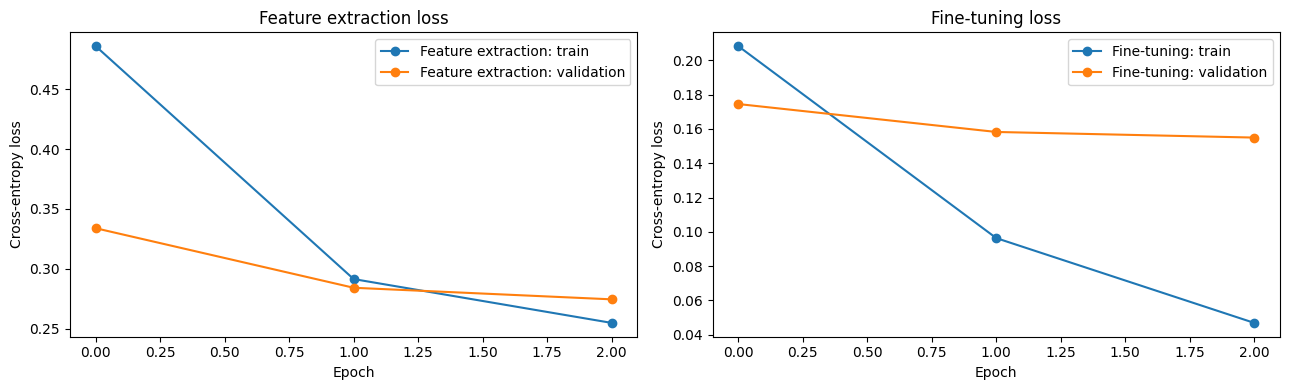

In [8]:
# Cell 7: Compare both training stages

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    history["feature_train_loss"], marker="o",
    label="Feature extraction: train",
)
axes[0].plot(
    history["feature_val_loss"], marker="o",
    label="Feature extraction: validation",
)
axes[0].set_title("Feature extraction loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(
    history["finetune_train_loss"], marker="o",
    label="Fine-tuning: train",
)
axes[1].plot(
    history["finetune_val_loss"], marker="o",
    label="Fine-tuning: validation",
)
axes[1].set_title("Fine-tuning loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
# Cell 8: Final test evaluation

test_loss, test_accuracy = evaluate(model, test_loader)

print(f"Final test loss: {test_loss:.4f}")
print(f"Final test accuracy: {test_accuracy:.2%}")

Final test loss: 0.1688
Final test accuracy: 94.71%


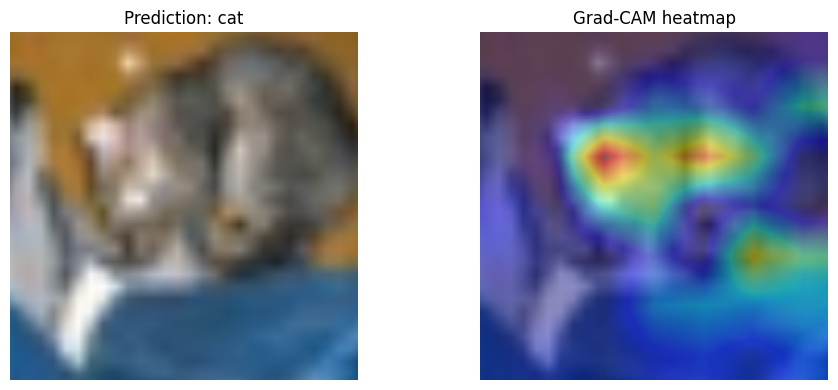

True label: cat
Predicted label: cat


In [10]:
# Cell 9: Grad-CAM for the final ResNet50 convolutional block

import torch.nn.functional as F


def grad_cam(model, image, target_class=None):
    model.eval()
    model.zero_grad(set_to_none=True)

    activations = {}
    gradients = {}

    target_layer = model.layer4[-1]

    def save_activation(module, inputs, output):
        activations["value"] = output

        # Capture the gradient flowing into the activation tensor.
        output.register_hook(
            lambda grad: gradients.__setitem__("value", grad)
        )

    handle = target_layer.register_forward_hook(save_activation)

    try:
        logits = model(image)

        if target_class is None:
            target_class = int(logits.argmax(dim=1)[0])

        # Backpropagate the selected class score.
        score = logits[0, target_class]
        score.backward()

        feature_maps = activations["value"]
        feature_gradients = gradients["value"]

        # Average gradients spatially to obtain channel weights.
        weights = feature_gradients.mean(dim=(2, 3), keepdim=True)

        # Weighted combination of feature maps.
        cam = (weights * feature_maps).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam,
            size=image.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )

        cam = cam[0, 0]
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        return cam.detach().cpu().numpy(), target_class, logits.detach()

    finally:
        handle.remove()


# Inspect one test image.
images, labels = next(iter(test_loader))
image = images[0:1].to(DEVICE)

cam, predicted_class, logits = grad_cam(model, image)

# Convert the normalized tensor back to RGB for display.
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

original = image[0].detach().cpu() * std + mean
original = original.permute(1, 2, 0).clamp(0, 1).numpy()

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title(f"Prediction: {CLASSES[predicted_class]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original)
plt.imshow(cam, cmap="jet", alpha=0.45)
plt.title("Grad-CAM heatmap")
plt.axis("off")

plt.tight_layout()
plt.show()

print("True label:", CLASSES[labels[0].item()])
print("Predicted label:", CLASSES[predicted_class])